In [1]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


# Load image and transcription

In [6]:
#path ="/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Feb2026/Processed/846531_HD_BA_WM_C_DNB_SM_J75-3-D1-GFP_R1/outs/"
path = "/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Feb2026/Processed/846531_HD_BA_WM_C_DNB_SM_J75-3-D1-GFP_R1/outs/binned_outputs/square_016um/"


In [7]:
adata_st = sc.read_visium(
    path=path,          # folder containing spatial/ and matrix/
    count_file="filtered_feature_bc_matrix.h5",
    load_images=True,
)

/lsf_tmp/289808573.tmpdir/ipykernel_2635360/3009433346.py:1: FutureWarning: Use `squidpy.read.visium` instead.
  adata_st = sc.read_visium(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [8]:
adata_st

AnnData object with n_obs × n_vars = 67254 × 19060
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

In [9]:
adata_st.var_names_make_unique()

Confirm spatial coordinates loaded

In [ ]:
print(adata_st.obsm["spatial"])          # (n_spots, 2) pixel coordinates
print(adata_st.uns["spatial"])           # image + scalefactors

# Quick tissue plot

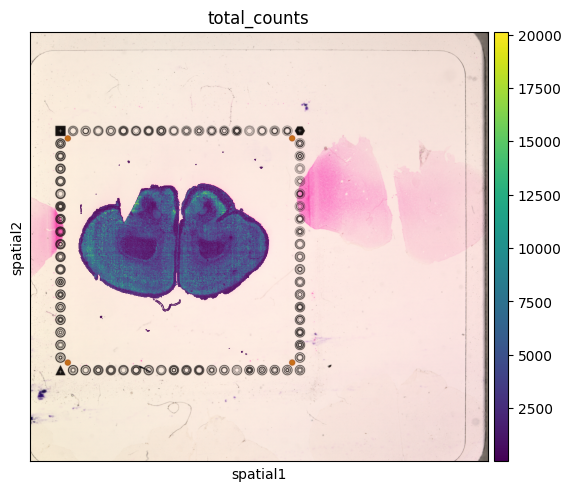

In [12]:
sc.pp.calculate_qc_metrics(adata_st, inplace=True)
sq.pl.spatial_scatter(adata_st, color="total_counts", size=1.5)
plt.savefig("spatial_total_counts_846531_HD_BA_WM_C_DNB_SM_J75-3-D1-GFP_R1.png",dpi=300,bbox_inches="tight")

# QC and normalization

In [13]:
sc.pp.calculate_qc_metrics(adata_st, inplace=True)

Spatial QC — plot metrics on tissue

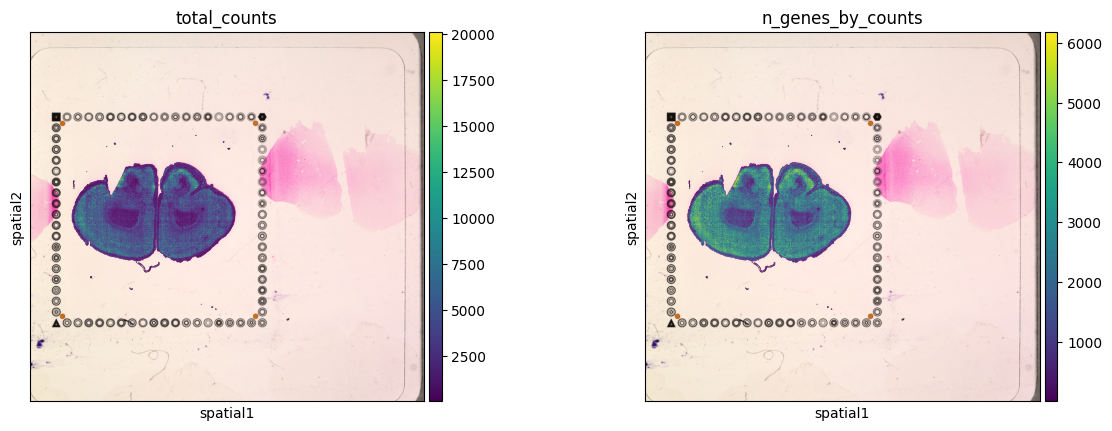

In [14]:
sq.pl.spatial_scatter(adata_st, color=["total_counts", "n_genes_by_counts"], size=1.5)

Filter low-quality spots

In [15]:
sc.pp.filter_cells(adata_st, min_counts=500)
sc.pp.filter_genes(adata_st, min_cells=10)

Stash raw counts

In [16]:
adata_st.layers["counts"] = adata_st.X.copy()
sc.pp.normalize_total(adata_st, target_sum=1e4)
sc.pp.log1p(adata_st)

# Spatially variable gene detection

spatial statistics

In [17]:
sq.gr.spatial_neighbors(adata_st, coord_type="grid", n_neighs=6)

Moran's I — spatial autocorrelation per gene

In [ ]:
sq.gr.spatial_autocorr(
    adata_st,
    mode="moran",
    n_perms=100,
    n_jobs=4,
)

  0%|          | 0/100 [00:00<?, ?/s]

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planni

Top spatially variable genes